
# Part 1 — Data Understanding & Exploration
### Hospital Readmission Prediction | Diabetes 130-US Hospitals (1999–2008)

This notebook is the **first deliverable**: it documents what the data contains,
what problems it has, and which patterns exist *before* any modelling.

**How to read this notebook**
- Every code cell is preceded by a markdown cell that explains **why** we run it.
- Comments inside the code (`#`) explain individual lines.
- The narrative answers, in order, the six Part 1 questions:
  1. What does the dataset contain?
  2. Target variable
  3. Missing values / duplicates / inconsistencies
  4. Candidate features
  5. Class balance
  6. Visual patterns



## 0. Setup and imports

| Import | Why we need it |
|---|---|
| `pandas` | loads the CSV into a DataFrame (table) + grouping/filtering |
| `numpy` | numeric helpers (arrays, log transforms, binning) |
| `matplotlib.pyplot` | the plotting engine — every chart is drawn by matplotlib |
| `seaborn` | statistical charts with far less code than raw matplotlib |
| `pathlib.Path` | file paths that work on any operating system |

`%matplotlib inline` is a Jupyter "magic command" (not Python) that tells the
notebook to draw plots *inside* the page instead of a separate window.


In [1]:
# --- Standard data-science imports -----------------------------------------
import warnings
warnings.filterwarnings("ignore")          # keep output readable for the reviewer

from pathlib import Path                    # OS-independent file paths
import numpy as np                          # numerical operations
import pandas as pd                         # tables (DataFrames)

import matplotlib.pyplot as plt             # base plotting library
import matplotlib.ticker as mtick          # format axes as percentages
import seaborn as sns                       # nicer statistical charts

# --- Make plots bigger and show a light grid by default ---------------------
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

# --- Locate the dataset relative to this notebook ---------------------------
# notebooks/01_...ipynb  ->  parent = notebooks/, parent.parent = project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV = PROJECT_ROOT / "data" / "raw" / "diabetic_data.csv"
print("Looking for data at:", CSV)
print("Exists:", CSV.exists())

Looking for data at: C:\Users\OSINOR TRILLIONS\hospital_readmission_ml\data\raw\diabetic_data.csv
Exists: True



## 1. What does the dataset contain? (Part 1, Q1)

Each row is **one hospital admission (an "encounter")**, not one patient.

Two critical read options:
- `na_values=["?"]` — in this dataset `?` is the official "missing" marker.
  Without it, missingness is invisible.
- `low_memory=False` — `payer_code` mixes text/numbers; this stops pandas
  from guessing different types for different chunks of the file.


In [2]:
# Load the raw data. One row = one inpatient stay.
df = pd.read_csv(
    CSV,
    na_values=["?"],          # treat '?' as missing
    low_memory=False,         # avoid mixed-type guessing warnings
)

print("Shape (rows, columns):", df.shape)
print("Unique stays (encounter_id):", df["encounter_id"].nunique())
print("Unique patients (patient_nbr):", df["patient_nbr"].nunique())
print("Patients with >1 stay:", (df["patient_nbr"].value_counts() > 1).sum())
print("Max stays for one patient:", df["patient_nbr"].value_counts().max())

Shape (rows, columns): (101766, 50)
Unique stays (encounter_id): 101766
Unique patients (patient_nbr): 71518
Patients with >1 stay: 16773
Max stays for one patient: 40



**Observation:** ~101,766 rows but only ~71,518 patients — about 30,000 stays
are repeat visits, and the most frequent patient returns **40 times**.

**Consequence (important):** if we split randomly by row, the same patient can
appear in both training and test data, and the model appears far better than it
is. Part 2 therefore splits **by patient**, not by row.

Below, the 50 columns grouped by meaning:


In [3]:
col_groups = {
    "identifiers"        : ["encounter_id", "patient_nbr"],
    "demographics"       : ["race", "gender", "age", "weight"],
    "admission/discharge": ["admission_type_id", "discharge_disposition_id",
                            "admission_source_id", "time_in_hospital"],
    "utilisation counts" : ["num_lab_procedures", "num_procedures", "num_medications",
                            "number_outpatient", "number_emergency",
                            "number_inpatient", "number_diagnoses"],
    "diagnoses"          : ["diag_1", "diag_2", "diag_3"],
    "lab results"        : ["max_glu_serum", "A1Cresult"],
    "medications (23)"   : ["metformin", "repaglinide", "nateglinide", "chlorpropamide",
                            "glimepiride", "acetohexamide", "glipizide", "glyburide",
                            "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
                            "miglitol", "troglitazone", "tolazamide", "examide",
                            "citoglipton", "insulin", "glyburide-metformin",
                            "glipizide-metformin", "glimepiride-pioglitazone",
                            "metformin-rosiglitazone", "metformin-pioglitazone"],
    "flags + target"     : ["change", "diabetesMed", "readmitted"],
}
all_listed = sum(col_groups.values(), [])
print("Columns grouped:", len(all_listed), "of", df.shape[1])
print("Not listed:", [c for c in df.columns if c not in all_listed])

for name, cols in col_groups.items():
    print(f"\n{name} ({len(cols)}):")
    print("  " + ", ".join(cols))

Columns grouped: 48 of 50
Not listed: ['payer_code', 'medical_specialty']

identifiers (2):
  encounter_id, patient_nbr

demographics (4):
  race, gender, age, weight

admission/discharge (4):
  admission_type_id, discharge_disposition_id, admission_source_id, time_in_hospital

utilisation counts (7):
  num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, number_diagnoses

diagnoses (3):
  diag_1, diag_2, diag_3

lab results (2):
  max_glu_serum, A1Cresult

medications (23) (23):
  metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone

flags + target (3):
  change, diabetesMed, readmitted


In [4]:
# Peek at the first 3 stays: .T transposes so we see columns down the page
df.head(3).T

,0,1,2
encounter_id,2278392,149190,64410
patient_nbr,8222157,55629189,86047875
race,Caucasian,Caucasian,AfricanAmerican
gender,Female,Female,Female
age,[0-10),[10-20),[20-30)
weight,NaN,NaN,NaN
admission_type_id,6,1,1
discharge_disposition_id,25,1,1
admission_source_id,1,7,7
time_in_hospital,1,3,2



## 2. Structural cleaning *before* analysis (Part 1, Q3 part A)

We do not silently delete anything — we only apply fixes whose justification is
obvious from the data itself, and we document each one.

**Step 2.1 — Remove rows that can never be readmitted (target leakage).**
`discharge_disposition_id` values `11, 19, 20, 21` mean the patient **died**
(during the stay or in hospice). A deceased patient cannot be readmitted within
30 days, so leaving them in teaches the model the shortcut
"expired -> definitely no readmission", which is useless in practice.

We remove them and print exactly how many rows were dropped.


In [5]:
died_ids = [11, 19, 20, 21]           # 'Expired' / 'Expired in hospice'
mask_died = df["discharge_disposition_id"].isin(died_ids)
print("Rows where the patient died:", mask_died.sum())
print("Readmission rate in those rows:", df.loc[mask_died, "readmitted"].value_counts().to_dict())
print("  -> all 'NO': mathematically impossible to be a positive, i.e. leakage.")

df = df[~mask_died].copy()             # keep everyone else
print("\nRows after removing deceased:", len(df))

Rows where the patient died: 1652
Readmission rate in those rows: {'NO': 1652}
  -> all 'NO': mathematically impossible to be a positive, i.e. leakage.



Rows after removing deceased: 100114



**Step 2.2 — Rows with no recorded outcome.** If `readmitted` were missing we
could not use the row for training. (There are none here, but a real dataset
should always be checked.)


In [6]:
print("Missing 'readmitted':", df["readmitted"].isna().sum(), "-> no action needed")

Missing 'readmitted': 0 -> no action needed



**Step 2.3 — Invalid / uninformative values.**
- `gender = "Unknown/Invalid"` appears in only ~3 rows — we keep them for now;
  they are too few to matter and will be grouped as "Other" later if needed.
- Two drug columns (`examide`, `citoglipton`) hold the single value `No` in
  every row: constant columns carry **zero information** and are dropped.


In [7]:
print("Gender values:", df["gender"].value_counts(dropna=False).to_dict())

# A column is useless if it has only 1 distinct value.
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("\nConstant columns (dropped):", constant_cols)
print(df[constant_cols].apply(lambda s: s.value_counts(dropna=False).to_dict()).to_dict())
df = df.drop(columns=constant_cols)
print("Columns remaining:", df.shape[1])

Gender values: {'Female': 53861, 'Male': 46250, 'Unknown/Invalid': 3}



Constant columns (dropped): ['examide', 'citoglipton']
{'examide': {'No': 100114}, 'citoglipton': {'No': 100114}}
Columns remaining: 48



## 3. The target variable (Part 1, Q2)

`readmitted` has **three** values, but the hospital's question is binary:
*"will this patient come back within 30 days?"*

| raw value | meaning | our label |
|---|---|---|
| `<30` | readmitted within 30 days | **1** |
| `>30` | readmitted, but later than 30 days | 0 |
| `NO` | not readmitted in the recorded window | 0 |

> Why merge `>30` with `NO`? Because the operational decision (book a follow-up,
> arrange home care) only exists for the 30-day window. A model that separates
> `>30` from `NO` answers a different, easier question than the one asked.


In [8]:
print("Raw 'readmitted' values:")
print(df["readmitted"].value_counts().to_string())

# Binary target: 1 = came back within 30 days
df["readmit_30d"] = (df["readmitted"] == "<30").astype(int)

print()
print("Binary target counts (0 = not <30 days, 1 = readmitted <30 days):")
print(df["readmit_30d"].value_counts().to_string())
print()
print(f"Positive rate: {df['readmit_30d'].mean():.4f}  (~1 positive per "
      f"{1/df['readmit_30d'].mean():.1f} negatives)")

Raw 'readmitted' values:
readmitted
NO     53212
>30    35545
<30    11357

Binary target counts (0 = not <30 days, 1 = readmitted <30 days):
readmit_30d
0    88757
1    11357

Positive rate: 0.1134  (~1 positive per 8.8 negatives)


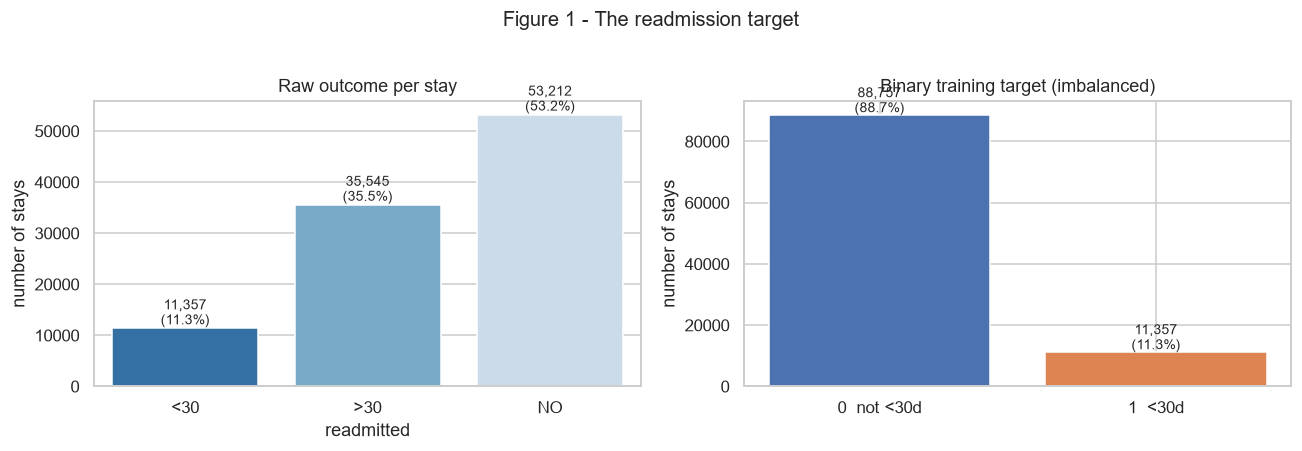

Accuracy of a model that ALWAYS predicts 0: 88.66%  <-- trivial and misleading


In [9]:
# --- Chart 1: the three raw categories vs the binary target -------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

counts = df["readmitted"].value_counts().reindex(["<30", ">30", "NO"])
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette="Blues_r")
ax[0].set_title("Raw outcome per stay")
ax[0].set_xlabel("readmitted")
ax[0].set_ylabel("number of stays")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 800, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=9)

pos = int(df["readmit_30d"].sum())
neg = int((df["readmit_30d"] == 0).sum())
ax[1].bar(["0  not <30d", "1  <30d"], [neg, pos], color=["#4C72B0", "#DD8452"])
ax[1].set_title("Binary training target (imbalanced)")
ax[1].set_ylabel("number of stays")
for i, v in enumerate([neg, pos]):
    ax[1].text(i, v + 800, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=9)

plt.suptitle("Figure 1 - The readmission target", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

print("Accuracy of a model that ALWAYS predicts 0: "
      f"{(df['readmit_30d'] == 0).mean():.2%}  <-- trivial and misleading")


## 4. Missing values (Part 1, Q3 part B)

Missingness is reported **per column**, sorted, so we can separate
"small gap" (fix it) from "mostly absent" (drop the column or treat as signal).


In [10]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})
missing = missing[missing["n_missing"] > 0].sort_values("pct_missing", ascending=False)
print(missing.to_string())
print()
print(f"Columns with no missing values: {df.shape[1] - len(missing)} of {df.shape[1]}")

                   n_missing  pct_missing
weight                 96958        96.85
max_glu_serum          94890        94.78
A1Cresult              83238        83.14
medical_specialty      49129        49.07
payer_code             39591        39.55
race                    2239         2.24
diag_3                  1421         1.42
diag_2                   358         0.36
diag_1                    21         0.02

Columns with no missing values: 40 of 49


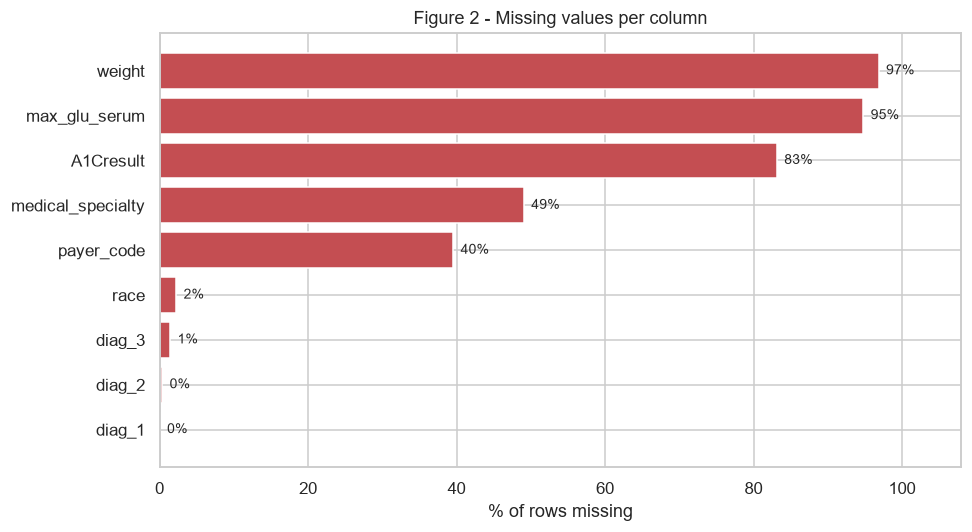

Reading: 'weight' is 97% missing -> unusable.
'medical_specialty' ~49% missing -> the absence itself may be informative,
so we keep it as its own category instead of dropping it.


In [11]:
# --- Chart 2: missing-data bar chart ------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
missing_sorted = missing.sort_values("pct_missing")
ax.barh(missing_sorted.index, missing_sorted["pct_missing"], color="#C44E52")
ax.set_xlabel("% of rows missing")
ax.set_title("Figure 2 - Missing values per column")
for y, (idx, row) in enumerate(missing_sorted.iterrows()):
    ax.text(row["pct_missing"] + 1, y, f"{row['pct_missing']:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 108)
plt.tight_layout()
plt.show()

print("Reading: 'weight' is 97% missing -> unusable.")
print("'medical_specialty' ~49% missing -> the absence itself may be informative,")
print("so we keep it as its own category instead of dropping it.")


### Decision table for missingness (each decision is justified)

| Column | % missing | Decision | Why |
|---|---|---|---|
| `weight` | ~97% | **Drop column** | nothing left to learn from |
| `medical_specialty` | ~49% | Keep, fill `"Missing"` | "no specialist" is a real signal |
| `payer_code` | ~40% | Fill `"Missing"` | low value, kept for completeness |
| `max_glu_serum` | ~95% | Fill `"Not measured"` | *whether* a test ran is information |
| `A1Cresult` | ~83% | Fill `"Not measured"` | same |
| `race` | ~2% | Fill `"Missing"` | tiny share, negligible distortion |
| `diag_1/2/3` | up to ~1.5% | Fill `"Missing"` | handled by ICD-9 grouping in section 8 |



## 5. Duplicates and inconsistencies (Part 1, Q3 part C)

- **Exact duplicate rows?** The dataset contains nearly none, but we always
  check — duplicates would let the same information sit in both train and test.
- **Repeated patients?** Yes, and that is the dangerous kind: the same
  `patient_nbr` appears in many stays (16,483 patients *after* the deceased rows
  were removed in section 2 — section 1 counted 16,773 *before* that removal).
  Handled by a **patient-level split** in notebook 02.
- **Inconsistent categories?** `gender` has a few `Unknown/Invalid` rows; several
  ID codes mean "Not mapped"/"Unknown"; `diag` fields contain junk values; some
  drug columns are constant.


In [12]:
print("Exact duplicate rows:", df.duplicated().sum())

per_patient = df["patient_nbr"].value_counts()
print("Patients with more than one stay:", (per_patient > 1).sum(),
      f"({(per_patient > 1).mean():.1%} of patients)")
print("Most stays by a single patient:", per_patient.max())

print()
print("gender:", df["gender"].value_counts(dropna=False).to_dict())

# Drug columns should only contain No / Steady / Up / Down
drug_cols = [c for c in df.columns
             if set(df[c].dropna().unique()) <= {"No", "Steady", "Up", "Down"}]
print("Drug-dose columns (No/Steady/Up/Down only):", len(drug_cols))
print("Example:", drug_cols[:4], "...")

Exact duplicate rows: 0
Patients with more than one stay: 16483 (23.4% of patients)
Most stays by a single patient: 40

gender: {'Female': 53861, 'Male': 46250, 'Unknown/Invalid': 3}


Drug-dose columns (No/Steady/Up/Down only): 21
Example: ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide'] ...



## 6. Is the dataset balanced? (Part 1, Q5)

**No — it is imbalanced: only ~11% of stays are positives (~1 : 8).**

Consequences we handle in Parts 2-3:
- Accuracy is a misleading headline metric (always predicting "no" scores ~89%).
- Use **recall / precision / F1 / PR-AUC**, plus `class_weight="balanced"` or
  resampling so the model does not simply learn to say "no" to everyone.


In [13]:
pos_rate = df["readmit_30d"].mean()
print(f"Positives: {df['readmit_30d'].sum():,}  ({pos_rate:.2%})")
print(f"Negatives: {(df['readmit_30d'] == 0).sum():,}  ({1-pos_rate:.2%})")
print(f"Imbalance ratio: 1 positive : {1/pos_rate:.1f} negatives")

Positives: 11,357  (11.34%)
Negatives: 88,757  (88.66%)
Imbalance ratio: 1 positive : 8.8 negatives



## 7. Which features might influence readmission? (Part 1, Q4)

Method: for every candidate feature, compute the readmission rate **within each
group** and look at the spread. A useful feature separates the groups; a flat
profile tells us the feature carries little signal on its own.

`groupby(...)["readmit_30d"].mean()` answers: *"among all stays with this
feature value, what fraction were readmitted within 30 days?"* — that fraction
is the readmission rate for the group.


In [14]:
def rate_table(col, min_n=100):
    """Readmission rate per value of `col`, keeping only groups with n >= min_n."""
    g = (df.groupby(col, observed=True)["readmit_30d"]
           .agg(n="count", readmit_rate="mean")
           .sort_values("readmit_rate", ascending=False))
    return g[g["n"] >= min_n].round(4)      # drop noise-prone tiny groups

for col in ["age", "race", "gender", "diabetesMed", "change", "insulin"]:
    print()
    print(f"--- {col} ---")
    print(rate_table(col).to_string())


--- age ---
              n  readmit_rate
age                          
[20-30)    1650        0.1430
[80-90)   16706        0.1244
[70-80)   25562        0.1201
[90-100)   2668        0.1162
[60-70)   22185        0.1128
[30-40)    3765        0.1126
[40-50)    9626        0.1067
[50-60)   17102        0.0975
[10-20)     690        0.0580
[0-10)      160        0.0188

--- race ---
                     n  readmit_rate
race                                
Caucasian        74845        0.1148
AfricanAmerican  18888        0.1141
Hispanic          2024        0.1047
Asian              632        0.1028
Other             1486        0.0976

--- gender ---
            n  readmit_rate
gender                     
Female  53861        0.1142
Male    46250        0.1125

--- diabetesMed ---


                 n  readmit_rate
diabetesMed                     
Yes          77272        0.1179
No           22842        0.0983

--- change ---
            n  readmit_rate
change                     
Ch      46443        0.1197
No      53671        0.1080

--- insulin ---


             n  readmit_rate
insulin                     
Down     12012        0.1414
Up       11091        0.1325
Steady   30331        0.1132
No       46680        0.1019



### The ID columns need `IDS_mapping.csv` to be readable

`discharge_disposition_id = 6` is meaningless until we look up the mapping file,
which tells us 6 = "Discharged/transferred to home with home health service".

The file is really **three tables glued together** with blank separator rows:
`admission_type_id`, `discharge_disposition_id`, `admission_source_id`.
The helper below slices out one table by taking every row *after* its title
until the next title, and returns a plain `{id: description}` dictionary.


In [15]:
MAP = PROJECT_ROOT / "data" / "raw" / "IDS_mapping.csv"
raw = pd.read_csv(MAP, header=None, names=["id", "description"],
                  skip_blank_lines=True, dtype=str)

TITLES = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

def split_map(start_title):
    """Return {id_number: description} for one of the 3 stacked tables."""
    start = raw.index[raw["id"] == start_title][0]
    later = [i for i in raw.index[raw["id"].isin(TITLES)] if i > start]
    end = min(later) if later else len(raw)         # stop before the next table
    block = raw.iloc[start + 1:end]
    block = block[block["id"].notna() & (block["id"].str.strip() != "")]
    return {int(str(i).strip()): str(d).strip()
            for i, d in zip(block["id"], block["description"])}

disc_map = split_map("discharge_disposition_id")
adm_map  = split_map("admission_type_id")
src_map  = split_map("admission_source_id")

print("mapping sizes -> admission:", len(adm_map),
      "| discharge:", len(disc_map), "| source:", len(src_map))
print("discharge 1 =", disc_map.get(1))
print("discharge 3 =", disc_map.get(3))
print("discharge 11 =", disc_map.get(11))

mapping sizes -> admission: 8 | discharge: 30 | source: 25
discharge 1 = Discharged to home
discharge 3 = Discharged/transferred to SNF
discharge 11 = Expired


In [16]:
# Readmission rate by discharge destination, with human-readable labels
g = (df.groupby("discharge_disposition_id", observed=True)["readmit_30d"]
       .agg(n="count", readmit_rate="mean"))
g["destination"] = g.index.map(disc_map)            # dict lookup: id -> label
g = g[g["n"] >= 100].sort_values("readmit_rate", ascending=False)
print(g.round(4).to_string())

print()
print("NOTE: the lowest groups are hospice / long-term-care patients who have a")
print("very low risk by construction; the deceased rows were removed earlier.")

                              n  readmit_rate                                                                                                destination
discharge_disposition_id                                                                                                                                
28                          139        0.3669  Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital
22                         1993        0.2770                          Discharged/transferred to another rehab fac including rehab units of a hospital .
5                          1184        0.2086                                       Discharged/transferred to another type of inpatient care institution
2                          2128        0.1607                                                      Discharged/transferred to another short term hospital
3                         13954        0.1466                                     


### Chart: readmission rate by discharge destination


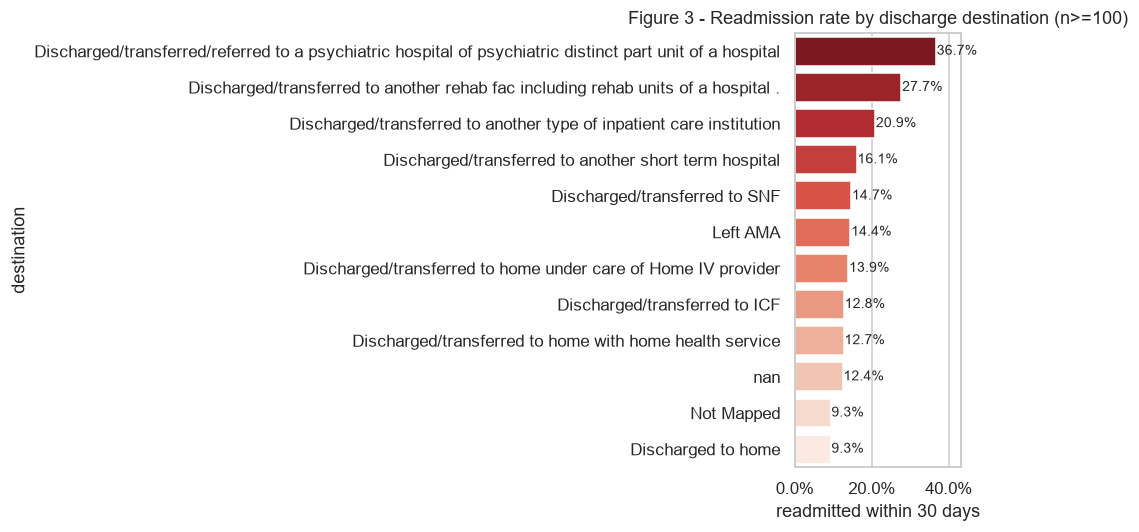

In [17]:
# --- Chart 3: readmit rate by discharge destination ---------------------------
plot = g.head(12)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=plot["readmit_rate"], y=plot["destination"], ax=ax, palette="Reds_r")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Figure 3 - Readmission rate by discharge destination (n>=100)")
ax.set_xlabel("readmitted within 30 days")
for y, v in enumerate(plot["readmit_rate"]):
    ax.text(v + 0.002, y, f"{v:.1%}", va="center", fontsize=9)
ax.set_xlim(0, plot["readmit_rate"].max() * 1.18)
plt.tight_layout()
plt.show()


### The strongest single pattern: prior inpatient visits


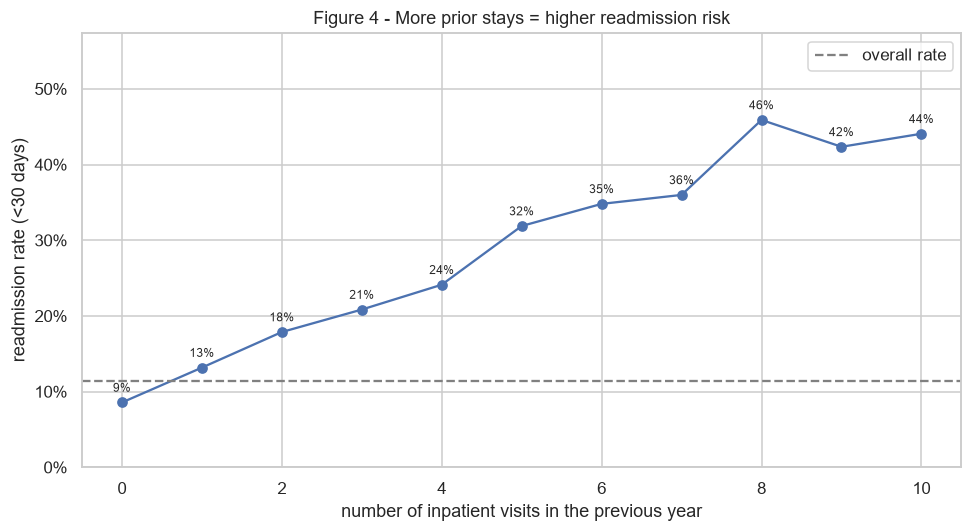

                      n  readmit_rate
number_inpatient                     
0                 66672        0.0856
1                 19163        0.1317
2                  7382        0.1787
3                  3321        0.2084
4                  1588        0.2412
5                   800        0.3188
6                   477        0.3480
7                   264        0.3598
8                   146        0.4589
9                   111        0.4234
10                   59        0.4407


In [18]:
# --- Chart 4: the monotone relationship --------------------------------------
g2 = (df.groupby("number_inpatient", observed=True)["readmit_30d"]
        .agg(n="count", readmit_rate="mean"))
g2 = g2[g2["n"] >= 50]                      # skip tiny high-count groups

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(g2.index, g2["readmit_rate"], marker="o", color="#4C72B0")
ax.axhline(df["readmit_30d"].mean(), color="grey", ls="--", label="overall rate")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("number of inpatient visits in the previous year")
ax.set_ylabel("readmission rate (<30 days)")
ax.set_title("Figure 4 - More prior stays = higher readmission risk")
ax.legend()
for x, y in zip(g2.index, g2["readmit_rate"]):
    ax.annotate(f"{y:.0%}", (x, y), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=8)
ax.set_ylim(0, g2["readmit_rate"].max() * 1.25)
plt.tight_layout()
plt.show()

print(g2.round(4).to_string())


### Age, utilisation, and diagnosis codes


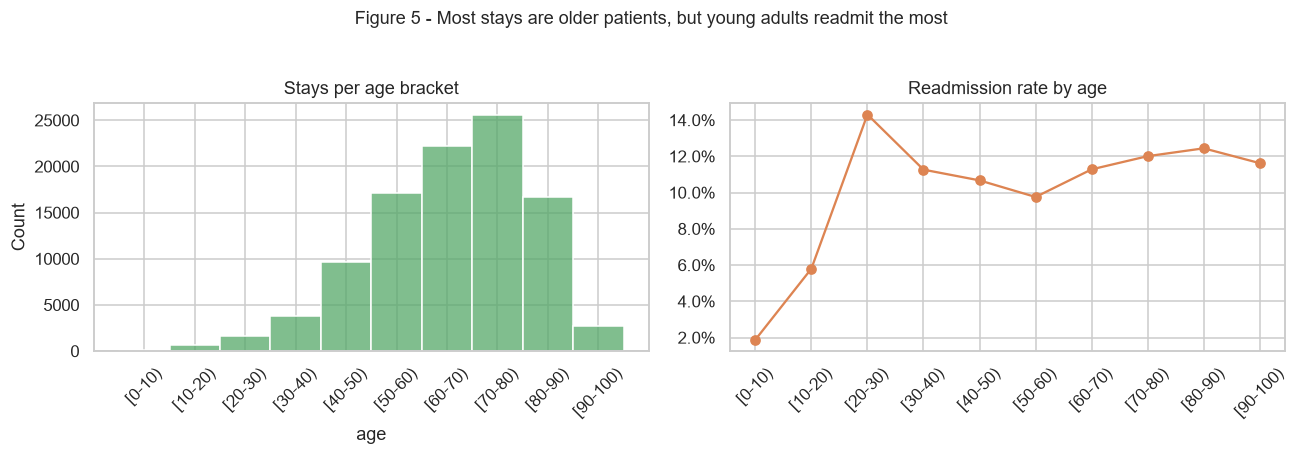

In [19]:
# --- Chart 5: age distribution + age vs readmit rate -------------------------
age_order = sorted(df["age"].dropna().unique())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="age", ax=ax[0], color="#55A868")
ax[0].set_title("Stays per age bracket")
ax[0].tick_params(axis="x", rotation=45)

by_age = (df.groupby("age", observed=True)["readmit_30d"].mean()
            .reindex(age_order))
ax[1].plot(age_order, by_age.values, marker="o", color="#DD8452")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[1].set_title("Readmission rate by age")
ax[1].tick_params(axis="x", rotation=45)
plt.suptitle("Figure 5 - Most stays are older patients, but young adults readmit the most",
             y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

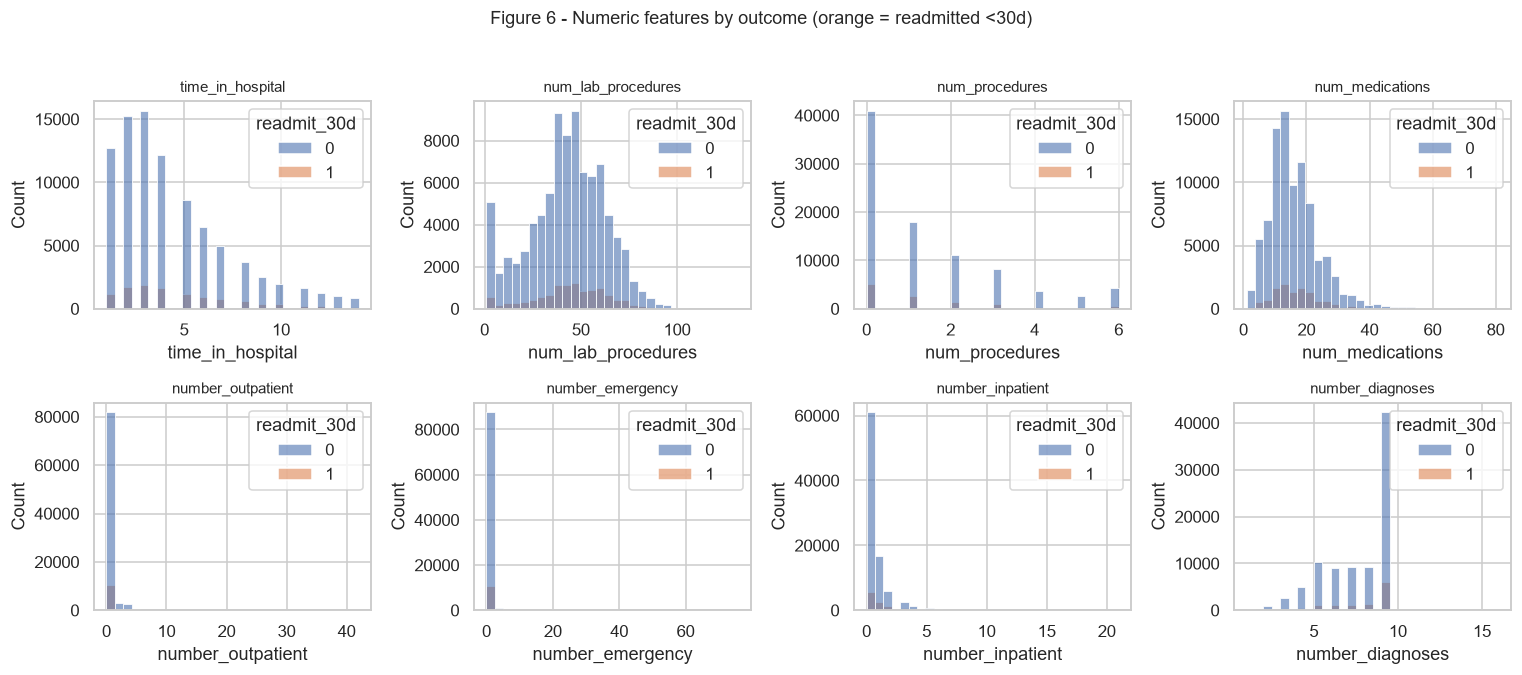

In [20]:
# --- Chart 6: utilisation distributions by outcome ---------------------------
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
            "num_medications", "number_outpatient", "number_emergency",
            "number_inpatient", "number_diagnoses"]

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue="readmit_30d", ax=ax, bins=30,
                 palette={0: "#4C72B0", 1: "#DD8452"}, alpha=0.6)
    ax.set_title(c, fontsize=10)
plt.suptitle("Figure 6 - Numeric features by outcome (orange = readmitted <30d)",
             y=1.02, fontsize=12)
plt.tight_layout()
plt.show()


## 8. Diagnosis codes (ICD-9) — turning ~17,000 codes into 9 clinical groups

`diag_1/2/3` are raw ICD-9 codes (`428`, `250.83`, `V58`, ...). Trees can split
on the raw string, but a **grouped** version is far more interpretable and
matches how clinicians talk (circulatory, respiratory, ...).

Grouping logic (a standard shortcut from the readmission literature):
- `250.xx`                       → diabetes
- 390–459 / 785                  → circulatory
- 460–519 / 786                  → respiratory
- 520–579 / 787                  → digestive
- 140–239                        → neoplasms
- 800–999                        → injury
- 710–739                        → musculoskeletal
- 580–629 / 788                  → genitourinary
- codes starting `V` or `E`      → supplementary (not a disease)
- anything else / missing        → other


In [21]:
def icd9_group(code):
    """Map one ICD-9 code to a coarse clinical group."""
    if pd.isna(code):
        return "missing"
    s = str(code).strip()
    if s[0] in ("V", "E"):
        return "supplementary"
    try:
        n = float(s.split(".")[0])
    except ValueError:
        return "other"
    if 250 <= n < 251:                     # diabetes
        return "diabetes"
    if (390 <= n < 460) or n == 785:
        return "circulatory"
    if (460 <= n < 520) or n == 786:
        return "respiratory"
    if (520 <= n < 580) or n == 787:
        return "digestive"
    if 140 <= n < 240:
        return "neoplasms"
    if 800 <= n < 1000:
        return "injury"
    if 710 <= n < 740:
        return "musculoskeletal"
    if (580 <= n < 630) or n == 788:
        return "genitourinary"
    return "other"

for c in ["diag_1", "diag_2", "diag_3"]:
    df[f"{c}_grp"] = df[c].map(icd9_group)

groups = pd.DataFrame({
    "diag_1": df["diag_1_grp"].value_counts(),
    "diag_2": df["diag_2_grp"].value_counts(),
    "diag_3": df["diag_3_grp"].value_counts(),
})
print(groups.to_string())

                 diag_1  diag_2  diag_3
circulatory       29881   31370   29789
diabetes           8693   12722   17027
digestive          9380    4114    3885
genitourinary      5054    8233    6519
injury             6881    2390    1905
missing              21     358    1421
musculoskeletal    4944    1762    1903
neoplasms          3299    2452    1773
other             16248   23683   23761
respiratory       14074   10506    7096
supplementary      1639    2524    5035


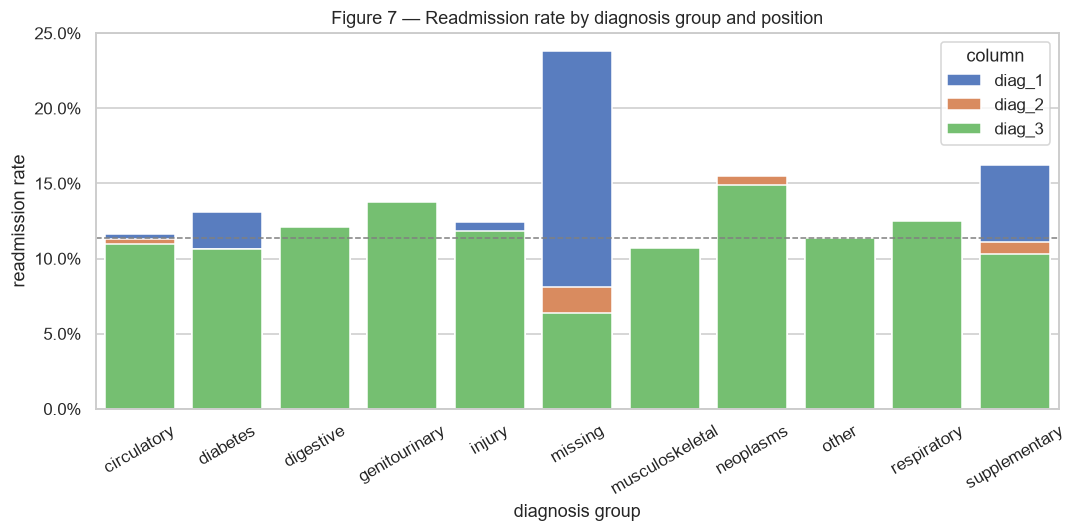

Readmit rate per group (diag_1):
                     n  readmit_rate
diag_1_grp                          
missing             21        0.2381
supplementary     1639        0.1623
diabetes          8693        0.1308
injury            6881        0.1241
circulatory      29881        0.1166
other            16248        0.1120
genitourinary     5054        0.1098
digestive         9380        0.1082
neoplasms         3299        0.1049
respiratory      14074        0.0997
musculoskeletal   4944        0.0953


In [22]:
# --- Chart 8: readmit rate per diagnosis group, by position -------------------
data = []
for c in ["diag_1", "diag_2", "diag_3"]:
    g = (df.groupby(f"{c}_grp", observed=True)["readmit_30d"]
           .agg(n="count", readmit_rate="mean").reset_index())
    g["column"] = c
    data.append(g)
icd = pd.concat(data)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=icd, x="diag_1_grp", y="readmit_rate", hue="column", ax=ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Figure 7 — Readmission rate by diagnosis group and position")
ax.set_xlabel("diagnosis group")
ax.set_ylabel("readmission rate")
ax.tick_params(axis="x", rotation=30)
ax.axhline(df["readmit_30d"].mean(), color="grey", ls="--", lw=1)
plt.tight_layout()
plt.show()

print("Readmit rate per group (diag_1):")
print(icd[icd["column"] == "diag_1"].set_index("diag_1_grp")
        .round(4)[["n", "readmit_rate"]].sort_values("readmit_rate", ascending=False).to_string())


## 9. Numeric correlations with the target

Correlation answers only *"does this number move together with readmission?"* —
it cannot capture non-linear effects (like prior visits, where risk jumps at 1
stay and keeps rising), which is why we use it for triage, not as proof.


In [23]:
corr = (df[num_cols + ["readmit_30d"]].corr()["readmit_30d"]
          .drop("readmit_30d").sort_values(key=abs, ascending=False).round(3))
print(corr.to_string())

number_inpatient      0.168
number_emergency      0.061
number_diagnoses      0.052
time_in_hospital      0.046
num_medications       0.041
num_lab_procedures    0.023
number_outpatient     0.019
num_procedures       -0.010


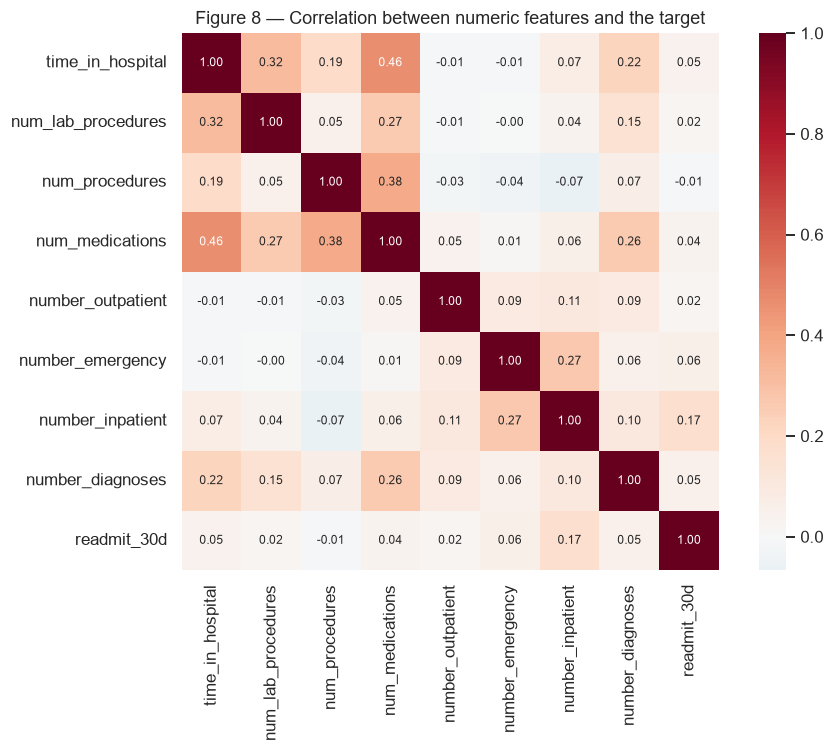

In [24]:
# --- Chart 9: correlation heatmap ---------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[num_cols + ["readmit_30d"]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, square=True, ax=ax, annot_kws={"size": 8})
ax.set_title("Figure 8 — Correlation between numeric features and the target")
plt.tight_layout()
plt.show()


## 10. Part 1 summary — what we learned about the data

**Structure**
- 101,766 stays of 71,518 diabetic patients; one row = one admission.
- 23.4% of patients have more than one stay (up to 40) — so we must split by
  **patient** (done in Part 2) or the test set leaks.

**Target**
- Binary `readmit_30d` = (`readmitted == "<30"`).
- **11.34% positives (11,357 of 100,114 rows)** — imbalanced, so accuracy is a trap.

**Data quality**
- `weight` missing for ~97% → will be dropped (executed in notebook 02).
- `medical_specialty`, `payer_code`, lab results missing for 40–95% — we keep them
  as their own "Missing" category because *being untested* is itself informative.
- Deceased patients (`discharge_disposition_id` 11/19/20/21) removed: they can
  never be readmitted → target leakage.
- Constant drug columns `examide` / `citoglipton` (single value `No`) dropped.

**Useful patterns**
1. `number_inpatient` is the standout: **8% → 45%** as prior stays go 0 → 8.
2. Discharge destination spreads from ~4.8% (hospice) to **36.7%** (psychiatric
   units); the 0% group (expired) was removed as leakage.
3. Utilisation counts (medications, diagnoses, labs) are all slightly higher for
   readmitted patients.
4. Age is non-linear: young adults (20–30) readmit most, seniors slightly less.
5. Race and gender are essentially flat — weak predictors and a fairness risk.
6. Diagnoses matter modestly; neoplasms as a secondary diagnosis stand out.


In [25]:
# --- Save the structurally-cleaned dataset for notebook 02 --------------------
OUT = PROJECT_ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

# The raw 3-way target has served its purpose; the processed file carries the binary target
df_out = df.drop(columns=["readmitted"])
out_path = OUT / "diabetes_clean_stage1.csv"
df_out.to_csv(out_path, index=False)
print("Saved:", out_path)
print("Shape written:", df_out.shape)
print("Columns:", len(df_out.columns))

Saved: C:\Users\OSINOR TRILLIONS\hospital_readmission_ml\data\processed\diabetes_clean_stage1.csv
Shape written: (100114, 51)
Columns: 51



---
**End of Part 1.** Next notebook: `02_preprocessing_and_modeling.ipynb`
(missing-value encoding, patient-level train/test split, three models,
evaluation, SHAP, and the healthcare discussion).
